In [13]:
# pip install scikit-learn torch torchvision matplotlib pandas

In [14]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd()
while not (REPO_ROOT / "utils" / "dataloader.py").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "utils"))

import pandas as pd

import torch
from dataloader import get_dataloaders, load_split

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

## Load dataset + test/validate/train split
Fashion MNIST splitted 60k samples for training + 10k for testing. 
Split 60k samples into 80% training set / 20% validating set

In [15]:
(X_train, y_train), (X_validate, y_validate), (X_test, y_test) = load_split("fashion_mnist")

print(f"Raw data type: {X_train.dtype}")
print(f"Raw pixel value range: {X_train.min().item()} to {X_train.max().item()}")

Raw data type: torch.uint8
Raw pixel value range: 0 to 255


## EDA & Preprocessing

In [16]:
def scale_tensor(tensor: torch.Tensor) -> torch.Tensor:
    tensor = tensor.float()
    return (tensor - tensor.min()) / (tensor.max() - tensor.min())

def z_score_normalize(tensor: torch.Tensor) -> torch.Tensor:
    tensor = tensor.float()
    return (tensor - tensor.mean()) / tensor.std()

### EDA

In [17]:
# Scale with statistics from the training split only, then apply the same
# transform to validation and test to avoid leakage between splits.
X_train = X_train.float()
X_validate = X_validate.float()
X_test = X_test.float()

train_min = X_train.min()
train_max = X_train.max()

X_train = (X_train - train_min) / (train_max - train_min)
X_validate = (X_validate - train_min) / (train_max - train_min)
X_test = (X_test - train_min) / (train_max - train_min)

SPLITS = {
    "training": (X_train, y_train),
    "validation": (X_validate, y_validate),
    "testing": (X_test, y_test)
}

for split_name, (split_data, split_labels) in SPLITS.items():
    class_counts = {i: count.item() for i, count in enumerate(torch.bincount(split_labels))}
    print(
        f"{split_name.capitalize()} set size: {len(split_data)}\n",
        f"{split_name.capitalize()} set shape: {tuple(split_data.shape)}, {tuple(split_labels.shape)}\n",
        f"Class distribution in {split_name} set:\n{class_counts}\n")

print("Fashion-MNIST is balanced: 4,800 training / 1,200 validation / 1,000 test images per class.")


Training set size: 48000
 Training set shape: (48000, 1, 28, 28), (48000,)
 Class distribution in training set:
{0: 4800, 1: 4800, 2: 4800, 3: 4800, 4: 4800, 5: 4800, 6: 4800, 7: 4800, 8: 4800, 9: 4800}

Validation set size: 12000
 Validation set shape: (12000, 1, 28, 28), (12000,)
 Class distribution in validation set:
{0: 1200, 1: 1200, 2: 1200, 3: 1200, 4: 1200, 5: 1200, 6: 1200, 7: 1200, 8: 1200, 9: 1200}

Testing set size: 10000
 Testing set shape: (10000, 1, 28, 28), (10000,)
 Class distribution in testing set:
{0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000, 6: 1000, 7: 1000, 8: 1000, 9: 1000}

Fashion-MNIST is balanced: 4,800 training / 1,200 validation / 1,000 test images per class.


Fashion-MNIST is balanced: 10 classes, with 4,800 training, 1,200 validation,
and 1,000 test images per class. No class-imbalance correction is therefore
required for the main comparison.


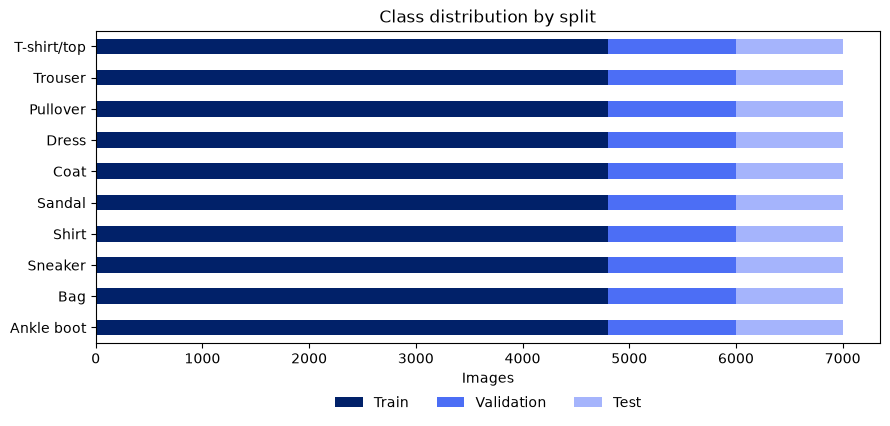

In [18]:
CLASSES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot",
]

FIG_DIR = REPO_ROOT / "assignment1" / "results" / "eda"
FIG_DIR.mkdir(parents=True, exist_ok=True)

counts = pd.DataFrame({
    "Train": torch.bincount(y_train, minlength=10).tolist(),
    "Validation": torch.bincount(y_validate, minlength=10).tolist(),
    "Test": torch.bincount(y_test, minlength=10).tolist(),
}, index=CLASSES)
counts.iloc[::-1].plot.barh(stacked=True, figsize=(9, 4.4),
                            color=["#012169", "#4c6ef5", "#a5b4fc"])
plt.title("Class distribution by split")
plt.xlabel("Images")
plt.ylabel("")
plt.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3)
plt.tight_layout()
plt.savefig(FIG_DIR / "class_balance.png", dpi=160)
plt.show()


#### Inspect pixel value distribution in the training set

Pixel statistics summary:
                  0
count  3.763200e+07
mean   2.862529e-01
std    3.531739e-01
min    0.000000e+00
25%    0.000000e+00
50%    0.000000e+00
75%    6.392157e-01
max    1.000000e+00


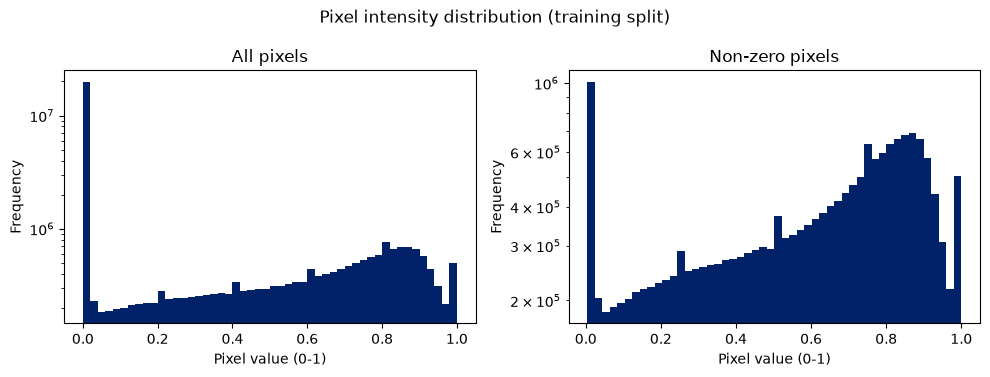

In [19]:
BINS = 50
X_df_train = pd.DataFrame(X_train.view(-1).numpy())

print(f"Pixel statistics summary:")
print(X_df_train.describe())

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, values, title in zip(
    axes, (X_train.flatten(), X_train[X_train > 0]), ("All pixels", "Non-zero pixels")
):
    ax.hist(values.numpy(), bins=BINS, color="#012169")
    ax.set(title=title, xlabel="Pixel value (0-1)", ylabel="Frequency", yscale="log")
fig.suptitle("Pixel intensity distribution (training split)")
fig.tight_layout()
plt.savefig(FIG_DIR / "pixel_distribution.png", dpi=160)
plt.show()


#### Inspect non-zero pixel value distribution in the training set

In [20]:
non_zero_pixels = X_df_train.copy()
non_zero_pixels = non_zero_pixels[non_zero_pixels > 0].dropna()

print(f"Non-zero pixel statistics summary:")
print(non_zero_pixels.describe())

print(f"\nTop 5 most frequent non-zero pixel values:")
freq_counts = pd.Series(non_zero_pixels.values.flatten()).value_counts(bins=BINS)
print(freq_counts.head(5))


Non-zero pixel statistics summary:
                  0
count  1.873980e+07
mean   5.748336e-01
std    2.908472e-01
min    3.921569e-03
25%    3.450980e-01
50%    6.431373e-01
75%    8.235294e-01
max    1.000000e+00

Top 5 most frequent non-zero pixel values:
(0.0019299999999999999, 0.0238]    1008462
(0.861, 0.88]                       689627
(0.841, 0.861]                      682593
(0.88, 0.9]                         662355
(0.821, 0.841]                      660081
Name: count, dtype: int64


#### Inspecting near-black pixels

In [21]:
NEAR_BLACK_UPPER_THRESHOLD = 0.0238
near_black_pixels = X_df_train.copy()
near_black_pixels = near_black_pixels[
    near_black_pixels.gt(0) & near_black_pixels.le(NEAR_BLACK_UPPER_THRESHOLD)
].dropna()

print(f"Near-black pixel statistics summary:")
print(near_black_pixels.describe())

print(f"Frequency of near-black pixel values:")
freq_counts = pd.Series(near_black_pixels.values.flatten()).value_counts()

print(freq_counts)


Near-black pixel statistics summary:
                  0
count  1.008462e+06
mean   9.618588e-03
std    6.068752e-03
min    3.921569e-03
25%    3.921569e-03
50%    7.843138e-03
75%    1.176471e-02
max    2.352941e-02
Frequency of near-black pixel values:
0.003922    381962
0.007843    229630
0.011765    153729
0.015686    105099
0.019608     77562
0.023529     60480
Name: count, dtype: int64



Visualizing sample images for each class:


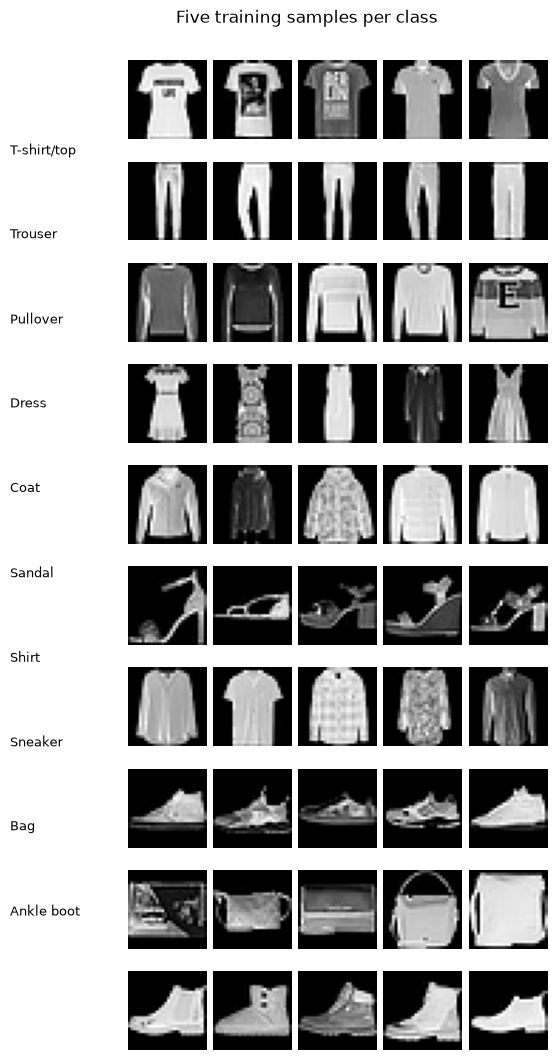

In [22]:
num_classes = 10
images_per_class = 5

print(f"\nVisualizing sample images for each class:")
fig, axes = plt.subplots(10, images_per_class, figsize=(5.6, 10.8))
for class_index, row in enumerate(axes):
    for ax, index in zip(row, torch.nonzero(y_train == class_index).flatten()[:images_per_class]):
        ax.imshow(X_train[index].squeeze(), cmap="gray")
        ax.axis("off")
    fig.text(0.03, row[0].get_position().y0 + 0.035, CLASSES[class_index],
             ha="left", va="center", fontsize=9)
fig.suptitle("Five training samples per class", x=0.56)
fig.subplots_adjust(left=0.24, right=0.99, top=0.94, bottom=0.01,
                    wspace=0.08, hspace=0.08)
plt.savefig(FIG_DIR / "samples.png", dpi=160)
plt.show()


Most images are dominated by pure black background. Non-zero pixel distribution is predominantly  left-skewed but illustrates an abnormally high frequency of "near-black" pixels. These near-black pixels seem to outline the clothing items, but some are randomly scattered fragments. This indicates these pixels migt be shadows or random noise.

### Augmentation (EDA-only experiment)

The flip and near-black experiments below are exploratory only. `main.ipynb`
reloads the original split and does **not** use them, so the reported main
comparison uses no augmentation.


Class 5 samples after augmentation:


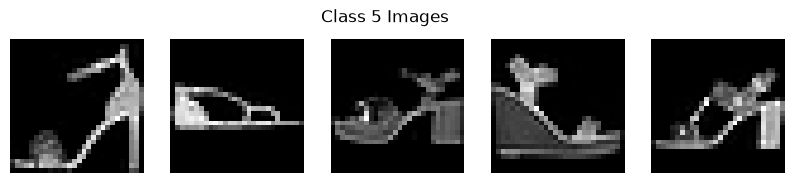

Class 7 samples after augmentation:


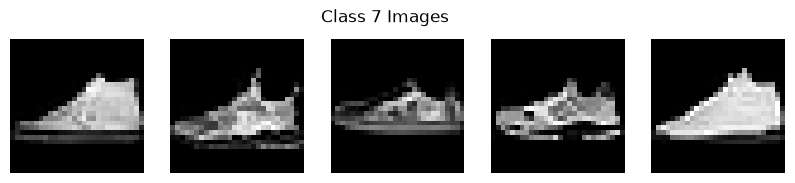

Class 9 samples after augmentation:


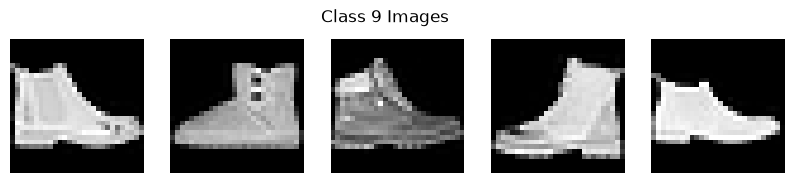

In [23]:
# Random horizontal flip for class 5, 7 and 9 (shoes, heels and boots).
# This is an EDA-only experiment, not part of the main training pipeline.
torch.manual_seed(42)
shoes_classes = [5, 7, 9]
shoes_mask = torch.isin(y_train, torch.tensor(shoes_classes))
random_mask = torch.rand(X_train.size(0)) < 0.5
flipped_mask = shoes_mask & random_mask

X_train[flipped_mask] = torch.flip(X_train[flipped_mask], dims=[-1])  # Flip horizontally

for class_index in shoes_classes:
    print(f"Class {class_index} samples after augmentation:")
    images = X_train[torch.nonzero(y_train == class_index).flatten()[:images_per_class]].squeeze()
    fig, axes = plt.subplots(1, images_per_class, figsize=(10, 2))
    for ax, image in zip(axes, images):
        ax.imshow(image, cmap="gray")
        ax.axis("off")
    fig.suptitle(f"Class {class_index} Images")
    plt.savefig(FIG_DIR / f"augmentation_class_{class_index}.png", dpi=160)
    plt.show()


### Dataloader (EDA-only)

The loaders below use the modified training copy above. They are for inspection
only; `main.ipynb` builds its own loaders from the untouched split.


In [24]:
train_dataloader, validation_dataloader, test_dataloader = get_dataloaders(
    X_train, y_train, X_validate, y_validate, X_test, y_test
)